# Question:
### What is the problability of rolling a 1 on a D6?

# My Sim:
### Describe your simulation here:
### Random Process: rolling a d6
### One Trial: roll one d6
### Possible Outcomes: 1, 2, 3, 4, 5, 6
### Event: Rolling a 1

In [30]:
import pandas
import numpy
from fractions import Fraction
import matplotlib
import seaborn

from config import DiceConfig

In [31]:
def roll_dice(sides, total):
    # rolls a dice with a specified number of sides for a specified number of times
    rolls = numpy.random.randint(low=1, high=(sides + 1), size=total)
    return pandas.DataFrame(data=rolls, columns=["Roll"])

In [32]:
def dice_sample_space(sides):
    # creates a sample space in a list for a dice with a specified amount of sides
    i = 2
    sample_space = [1]
    while i <= sides:
        sample_space.append(i)
        i+=1
    return sample_space

In [33]:
def relative_frequency(roll, sample_size, sample):
    # calculates the relative frequency of a specified roll
    num_count = (sample["Roll"] == roll).sum()
    val = num_count/sample_size
    return val

In [34]:
def cum_sum_relative_frequency(roll_sum, rows_so_far):
    val = roll_sum / rows_so_far
    return val

In [35]:
def relative_frequency_so_far(roll, data):
    new_data = data.copy()
    is_one = new_data["Roll"] == roll
    cum_sum_of_roll = is_one.cumsum()
    total_rows_so_far = numpy.arange(1, len(new_data) + 1)
    
    new_data["Relative frequency so far"] = cum_sum_relative_frequency(cum_sum_of_roll, total_rows_so_far)
    return new_data

In [36]:
die = DiceConfig.die_number
rolls = DiceConfig.times_rolled
checked_number = DiceConfig.checked_number
graph_types = ("LINE", "DOT", "BAR")
current_roll = roll_dice(die, rolls)
current_roll_size = current_roll.index.size
# current_roll.head()

In [37]:
current_sample_space = dice_sample_space(die)
current_sample_space_size = len(current_sample_space)

In [38]:
ideal_probability = Fraction(1/len(current_sample_space)).limit_denominator()

In [39]:
current_relative_frequency = relative_frequency(checked_number, current_roll_size, current_roll)

In [40]:
current_roll = relative_frequency_so_far(checked_number, current_roll)
# current_roll_with_relative_frequency.head()

In [41]:
print(f"Number of possible outcomes: {len(current_sample_space)}")
print()
print(f"Ideal probability: {ideal_probability}")
print()
print(f"Relative frequency of {checked_number}: {Fraction(current_relative_frequency).limit_denominator()} (or {round(current_relative_frequency, 3)})")

Number of possible outcomes: 6

Ideal probability: 1/6

Relative frequency of 1: 79/500 (or 0.158)


Text(0.5, 0, 'Trials')

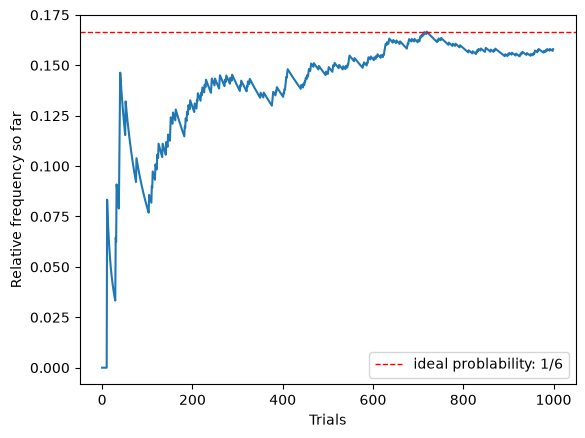

In [42]:
graph = seaborn.lineplot(data=current_roll, x=current_roll.index, y=current_roll.columns[1])
matplotlib.pyplot.axhline(ideal_probability, color="red", linestyle="--", linewidth=1, label=f"ideal problability: {ideal_probability}")
matplotlib.pyplot.legend()
matplotlib.pyplot.xlabel("Trials")

# My Conclusion
Answer: The ideal probablility is 0.167, and in this run of my simulation, I got 0.158. This graph showcases the ideal probability because the graph values moves closer to the ideal probability over the course of the simulation.